# Retards et contentieux : synthèse

Ce notebook mesure les retards (flux annuels), décrit le stock de contentieux en cours, l'effet et la régularité des appels téléphoniques, et le suivi des titres de recette.

Repères :
- **circuit** : relances Koha à 7 et 14 jours, appel téléphonique à partir de 28 jours, lettre de facture à 42 jours, puis titre de recette (fiches suivies dans le bloc `B_` de l'adhérent et dans les fichiers Excel de suivi) ;
- **particuliers** : catégories BIBL, MEDA, MEDB, MEDC, CSVT ;
- un prêt est **toujours emprunté** s'il figure dans les prêts en cours de Koha, sinon il est rendu ; tout est calculé à la **date de fraîcheur** des données ;
- **titre émis** : `N° titre` renseigné et différent de 0 (un titre annulé a été émis : l'usager a remboursé à la médiathèque) ; **dossier** : une ligne des fichiers de suivi ;
- **aucune donnée nominative n'est affichée** : ne pas ajouter de cellule montrant des lignes individuelles.

Le nettoyage des champs d'appel des personnes qui ne sont plus en retard se fait avec le script `adm_contentieux_nettoyage_appels.py`.

# Préparation des données
Cellules de calcul, sans affichage ; la dernière résume les contrôles de qualité.

In [1]:
import glob
import os
import re
import unicodedata

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")

from scipy import stats

from kiblib.utils.db import DbConn

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [2]:
db_conn = DbConn().create_engine()

PARTICULIERS = ['BIBL', 'MEDA', 'MEDB', 'MEDC', 'CSVT']
COLLECTIVITES = ['ECOL', 'CLAS', 'COLS', 'COLD', 'COLI']
DEBUT_HISTORIQUE = '2018-06-01'   # prêts chargés à partir de cette date
ANNEE_DEBUT = 2019                # première année d'échéance analysée
SEUILS = [0, 7, 14, 28, 42, 90, 180]
SEUIL_APPEL = 28                  # entrée dans le circuit (appel téléphonique)
SEUIL_CTX = 42                    # lettre de facture
SEUIL_TITRE_EUR = 15              # seuil de mise en recouvrement
TRANCHES_AGE = [-1, 11, 17, 24, 39, 59, 74, 200]
LIB_AGE = ['0-11', '12-17', '18-24', '25-39', '40-59', '60-74', '75+']
TRANCHES_STOCK = [SEUIL_APPEL, 42, 90, 180, 365, 730, 100000]
LIB_STOCK = ['29-42 j', '43-90 j', '91-180 j', '181-365 j', '1-2 ans', '> 2 ans']
DOSSIER_TITRES = os.path.join("..", "..", "titres")   # fichiers Excel de suivi (hors dépôt : données nominatives)

def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return c - h, c + h

def test_chi2(ct):
    chi2, p, ddl, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return f"χ² = {chi2:.1f}, ddl = {ddl}, p = {p:.2g}, V de Cramér = {v:.3f}"

def mcnemar(b, c):
    return stats.binomtest(b, b + c, 0.5).pvalue

def renseigne(s):
    return s.notna() & (s.astype(str).str.strip() != '')

def lire_date(s):
    s = s.astype(str).str.strip()
    d = pd.to_datetime(s, format='%Y-%m-%d', errors='coerce')
    return d.fillna(pd.to_datetime(s, format='%d/%m/%Y', errors='coerce'))

In [3]:
fraicheur = pd.Timestamp(pd.read_sql("""
    SELECT GREATEST((SELECT MAX(issuedate) FROM koha_prod.issues), (SELECT MAX(returndate) FROM koha_prod.old_issues))
""", db_conn).iloc[0, 0]).normalize()

In [4]:
p = pd.read_sql(f"""
SELECT borrowernumber, itemnumber, issuedate, date_due AS due_s, returndate AS ret_s,
       categorycode, age, sexe, fidelite, branchcode AS site_inscription
FROM statdb.stat_issues WHERE issuedate >= '{DEBUT_HISTORIQUE}'
""", db_conn).drop_duplicates(['itemnumber', 'issuedate'])
cours = pd.read_sql("SELECT itemnumber, issuedate, date_due AS due_k FROM koha_prod.issues", db_conn)
cours['en_cours'] = True
anciens = pd.read_sql(f"""
SELECT itemnumber, issuedate, date_due AS due_o, returndate AS ret_o
FROM koha_prod.old_issues WHERE issuedate >= '{DEBUT_HISTORIQUE}' AND itemnumber IS NOT NULL
""", db_conn).drop_duplicates(['itemnumber', 'issuedate'])
orphelins = pd.read_sql(f"""
SELECT issuedate, date_due AS due_orph, returndate AS ret_orph
FROM koha_prod.old_issues WHERE itemnumber IS NULL AND issuedate >= '{DEBUT_HISTORIQUE}'
""", db_conn)
orphelins = orphelins[~orphelins['issuedate'].duplicated(keep=False)]
exemplaires = pd.read_sql("""
SELECT it.itemnumber, it.itemlost, d.dernier_pret_exemplaire
FROM koha_prod.items it
LEFT JOIN (SELECT itemnumber, MAX(issuedate) AS dernier_pret_exemplaire FROM (
    SELECT itemnumber, issuedate FROM koha_prod.issues
    UNION ALL SELECT itemnumber, issuedate FROM koha_prod.old_issues WHERE itemnumber IS NOT NULL) t
    GROUP BY itemnumber) d ON d.itemnumber = it.itemnumber
""", db_conn)

p = (p.merge(cours.drop_duplicates(['itemnumber', 'issuedate']), on=['itemnumber', 'issuedate'], how='left')
      .merge(anciens, on=['itemnumber', 'issuedate'], how='left')
      .merge(orphelins, on='issuedate', how='left')
      .merge(exemplaires, on='itemnumber', how='left'))
p['en_cours'] = p['en_cours'].fillna(False).astype(bool)
a_completer = ~p['en_cours'] & p['ret_o'].isna()
p.loc[~a_completer, ['due_orph', 'ret_orph']] = None

p['echeance'] = pd.to_datetime(p['due_k'].fillna(p['due_o']).fillna(p['due_orph']).fillna(p['due_s']), errors='coerce').dt.normalize()
p['retour'] = pd.to_datetime(p['ret_o'].fillna(p['ret_orph']).fillna(p['ret_s']), errors='coerce').dt.normalize().where(~p['en_cours'])
p['retour_inconnu'] = ~p['en_cours'] & p['retour'].isna()
p.loc[p['retour'] > fraicheur, 'retour'] = pd.NaT   # retour postérieur à la fraîcheur : non rendu à cette date
p['non_rendu'] = p['retour'].isna() & ~p['retour_inconnu']
p['retard'] = (p['retour'].fillna(fraicheur) - p['echeance']).dt.days
p['retour_douteux'] = (~p['non_rendu'] & ~p['retour_inconnu'] & (p['issuedate'] == p['dernier_pret_exemplaire'])
                       & p['itemlost'].isin([1, 2]) & (p['retard'] > 0))
p['annee_echeance'] = p['echeance'].dt.year
p['mois_echeance'] = p['echeance'].dt.to_period('M')
p['tranche_age'] = pd.cut(pd.to_numeric(p['age'], errors='coerce'), TRANCHES_AGE, labels=LIB_AGE)


prets = p[p['categorycode'].isin(PARTICULIERS) & ~p['retour_inconnu'] & (p['echeance'] <= fraicheur)
          & (p['annee_echeance'] >= ANNEE_DEBUT)].copy()

In [5]:
adh = pd.read_sql("""
SELECT borrowernumber, cardnumber, surname, firstname, dateofbirth, categorycode, branchcode, dateexpiry,
       phone, mobile, email,
       B_address, B_address2, B_city, B_state, B_zipcode, B_country, contactnote
FROM koha_prod.borrowers
""", db_conn)

for champ, nom in [('B_address', 'date_appel'), ('B_city', 'date_tiers'), ('B_country', 'date_titre')]:
    adh[nom] = lire_date(adh[champ])
    adh[nom + '_illisible'] = renseigne(adh[champ]) & adh[nom].isna()

adh['resultat_appel'] = adh['B_address2'].where(adh['B_address2'].isin(['usager joint', 'message vocal', 'téléphone inconnu']))
etat = adh['B_state'].astype(str).str.strip()
adh['etat_titre'] = np.select([etat == '0', etat.str.fullmatch(r'\d{6,9}')], ['0 (< 15 €)', 'numéro'], default=None)
adh['tel'] = renseigne(adh['phone']) | renseigne(adh['mobile'])
adh['courriel'] = renseigne(adh['email'])

# montant facturé lu dans contactnote : "(7.90)" ou "- 7.90"
def montant(note):
    if not isinstance(note, str):
        return np.nan
    m = re.findall(r'(?:\(|-\s*)(\d+[.,]\d{1,2})', note)
    return sum(float(x.replace(',', '.')) for x in m) if m else np.nan
adh['montant_note'] = adh['contactnote'].map(montant)

susp = pd.read_sql("""
SELECT borrowernumber, MIN(created) AS date_suspension
FROM koha_prod.borrower_debarments WHERE type = 'OVERDUES' GROUP BY borrowernumber
""", db_conn)
adh = adh.merge(susp, on='borrowernumber', how='left')
adh['dernier_pret'] = adh['borrowernumber'].map(p.groupby('borrowernumber')['issuedate'].max())

In [6]:
# --- 1. taux de retard par année et par seuil (prêts et emprunteurs)
def depasse(df, s, plafond=False):
    x = df['retard'] > s
    if plafond:
        x = x | (df['retour_douteux'] & ((fraicheur - df['echeance']).dt.days > s))
    return x

def observable(df, s):
    return df[df['echeance'] + pd.Timedelta(days=s) <= fraicheur]

def par_emprunteur(df, s, plafond=False, periode='annee_echeance'):
    return depasse(df, s, plafond).groupby([df[periode], df['borrowernumber']]).any()

annees_completes = [a for a in range(ANNEE_DEBUT, fraicheur.year + 1)
                    if pd.Timestamp(f'{a}-12-31') + pd.Timedelta(days=max(SEUILS)) <= fraicheur]
ordre_seuils = [f'> {s} j' for s in SEUILS]
taux_prets, taux_emp, ecart_bornes = {}, {}, 0
for s in SEUILS:
    o = observable(prets, s)
    taux_prets[f'> {s} j'] = 100 * depasse(o, s).groupby(o['annee_echeance']).mean()
    bas, haut = par_emprunteur(o, s), par_emprunteur(o, s, plafond=True)
    taux_emp[f'> {s} j'] = 100 * bas.groupby(level=0).mean()
    ecart_bornes = max(ecart_bornes, (100 * (haut.groupby(level=0).mean() - bas.groupby(level=0).mean())).max())
taux = pd.concat({'% des prêts': pd.DataFrame(taux_prets), "% des emprunteurs (au moins 1 prêt)": pd.DataFrame(taux_emp)}, axis=1)
taux.insert(0, ('', 'emprunteurs'), prets.groupby('annee_echeance')['borrowernumber'].nunique())
taux.index.name = "année d'échéance"

# profil par âge, dernière année complète
a_der = annees_completes[-1]
d = prets[prets['annee_echeance'] == a_der].sort_values('echeance')
emp_age = pd.DataFrame({'tranche_age': d.groupby('borrowernumber')['tranche_age'].first()})
for s in [7, SEUIL_CTX, 180]:
    emp_age[f'> {s} j %'] = depasse(d, s).groupby(d['borrowernumber']).any()
age = emp_age.groupby('tranche_age').mean() * 100
age.insert(0, 'emprunteurs', emp_age.groupby('tranche_age').size())
v_age = test_chi2(pd.crosstab(emp_age['tranche_age'], emp_age[f'> {SEUIL_CTX} j %']))

# rappels avant échéance : part des emprunteurs en retard > 7 j par mois d'échéance, 2025 et 2026
rappels = pd.read_sql("""
SELECT YEAR(time_queued) AS annee, MONTH(time_queued) AS mois, COUNT(*) AS rappels
FROM koha_prod.message_queue WHERE letter_code IN ('PREDUE', 'PREDUEDGST') AND time_queued >= '2025-01-01'
GROUP BY annee, mois""", db_conn)
rappels.index = [pd.Period(f"{a}-{m:02d}", 'M') for a, m in zip(rappels['annee'], rappels['mois'])]
r = prets[(prets['echeance'] >= '2025-01-01') & (prets['echeance'] + pd.Timedelta(days=14) <= fraicheur)]
mensuel = 100 * par_emprunteur(r, 7, periode='mois_echeance').groupby(level=0).mean()
rap = pd.DataFrame({'> 7 j %': mensuel, 'rappels': rappels['rappels']})
rap['année'], rap['mois'] = rap.index.year, rap.index.month
comparaison_rappels = rap.pivot_table(index='mois', columns='année', values=['> 7 j %', 'rappels']).dropna(subset=[('> 7 j %', 2026)])
comparaison_rappels[('> 7 j %', 'écart 2026 - 2025')] = comparaison_rappels[('> 7 j %', 2026)] - comparaison_rappels[('> 7 j %', 2025)]

In [7]:
# --- 2. stock actuel (prêts en cours de plus de 28 jours de retard) et étape dans le circuit
actuels = pd.read_sql("""
SELECT i.borrowernumber, i.itemnumber, i.issuedate, i.date_due,
       it.replacementprice, it.itemlost, it.itype, it.biblionumber
FROM koha_prod.issues i
LEFT JOIN koha_prod.items it ON it.itemnumber = i.itemnumber
""", db_conn)
actuels['echeance'] = pd.to_datetime(actuels['date_due'], errors='coerce').dt.normalize()
actuels['retard'] = (fraicheur - actuels['echeance']).dt.days
actuels['prix'] = actuels['replacementprice'].where(actuels['replacementprice'] > 0)
prix_type = pd.read_sql("SELECT itype, replacementprice FROM koha_prod.items WHERE replacementprice > 0",
                        db_conn).groupby('itype')['replacementprice'].median()
actuels['prix_haut'] = actuels['prix'].fillna(actuels['itype'].map(prix_type)).fillna(prix_type.median())
actuels['prix_bas'] = actuels['prix'].fillna(0)
resa = pd.read_sql("SELECT DISTINCT biblionumber FROM koha_prod.reserves", db_conn)
actuels['titre_reserve'] = actuels['biblionumber'].isin(resa['biblionumber'])

en_retard = actuels[actuels['retard'] > SEUIL_APPEL]
stock = en_retard.groupby('borrowernumber').agg(
    docs=('itemnumber', 'size'), plus_ancienne_echeance=('echeance', 'min'), retard_max=('retard', 'max'),
    valeur_bas=('prix_bas', 'sum'), valeur_haut=('prix_haut', 'sum')).reset_index()
stock = stock.merge(adh, on='borrowernumber', how='left')
stock['tranche'] = pd.cut(stock['retard_max'], TRANCHES_STOCK, labels=LIB_STOCK)
stock['type'] = np.select([stock['categorycode'].isin(PARTICULIERS), stock['categorycode'].isin(COLLECTIVITES)],
                          ['particulier', 'collectivité'], default='autre (CGEN, personnel…)')

def etape(df, illisible_rattache):
    def lie(nom):
        return (df[nom] >= df['plus_ancienne_echeance']) | (df[nom + '_illisible'] & illisible_rattache)
    titre_lie, tiers_lie, appel_lie = lie('date_titre'), lie('date_tiers'), lie('date_appel')
    return pd.Series(np.select(
        [titre_lie & (df['etat_titre'] == 'numéro'),
         titre_lie & (df['etat_titre'] == '0 (< 15 €)'),
         titre_lie,
         tiers_lie,
         appel_lie & (df['resultat_appel'] == 'usager joint'),
         appel_lie & (df['resultat_appel'] == 'message vocal'),
         appel_lie & (df['resultat_appel'] == 'téléphone inconnu'),
         appel_lie,
         df['tel']],
        ['1 titre émis', '2 clos < 15 €', '3 titre daté sans numéro', '4 tiers demandé',
         '5a appelé : usager joint', '5b appelé : message vocal', '5c appelé : téléphone inconnu', '5d appelé : résultat non noté',
         '6a non traité, téléphone connu'],
        default='6b non traité, sans téléphone'), index=df.index)

stock['etape'] = etape(stock, illisible_rattache=True)
stock['etape_haut'] = etape(stock, illisible_rattache=False)
stock['bloc_dossier_anterieur'] = (renseigne(stock['B_address']) | renseigne(stock['B_country'])) & stock['etape'].str.startswith('6')
part = stock[stock['type'] == 'particulier'].copy()

# évolution du stock en fin de mois (particuliers)
mois_24 = pd.period_range((fraicheur - pd.DateOffset(months=24)).to_period('M'), fraicheur.to_period('M'), freq='M')
evolution = pd.Series({m: prets[(prets['echeance'] + pd.Timedelta(days=SEUIL_APPEL) < min(m.to_timestamp(how='end').normalize(), fraicheur))
                                & (prets['retour'].isna() | (prets['retour'] > min(m.to_timestamp(how='end').normalize(), fraicheur)))]['borrowernumber'].nunique()
                       for m in mois_24})

# suspensions automatiques arrêtées fin mars 2026
nouveaux = part[part['plus_ancienne_echeance'] + pd.Timedelta(days=SEUIL_CTX) >= pd.Timestamp('2026-03-30')]

In [8]:
# --- 3. appels : retours après l'appel, avant / après, régularité
DELAIS_RAPIDES = [1, 3, 7, 14, 28]
EFFET = "effet de l'appel (pts)"
base = p.loc[~p['retour_inconnu'], ['borrowernumber', 'itemnumber', 'issuedate', 'echeance', 'retour', 'en_cours']]
ap_r = adh[(adh['date_appel'] >= '2023-01-01') & (adh['date_appel'] <= fraicheur - pd.Timedelta(days=max(DELAIS_RAPIDES)))
           & adh['resultat_appel'].notna()][['borrowernumber', 'date_appel', 'resultat_appel', 'B_address']].copy()
ap_r['date_suspecte'] = ap_r['date_appel'].dt.day.eq(20) & ap_r['B_address'].astype(str).str.strip().str.fullmatch(r'\d{2}/\d{2}/\d{4}')
hh = base.merge(ap_r.drop(columns='B_address'), on='borrowernumber')

def non_rendu_a(df, jour):
    # prêts visés par l'appel : plus de 28 jours de retard à la date 'jour' (seuil du rapport Koha 207), et toujours dehors
    return ((df['issuedate'] < jour) & ((jour - df['echeance']).dt.days > SEUIL_APPEL)
            & (df['en_cours'] | (df['retour'] > jour)))

au_jour = hh[non_rendu_a(hh, hh['date_appel'])].copy()
au_jour['retard_appel'] = (au_jour['date_appel'] - au_jour['echeance']).dt.days
for j in DELAIS_RAPIDES:
    au_jour[f'{j} j'] = au_jour['retour'].notna() & (au_jour['retour'] <= au_jour['date_appel'] + pd.Timedelta(days=j))
pers_r = au_jour.groupby(['borrowernumber', 'date_appel', 'resultat_appel']).agg(
    retard=('retard_appel', 'max'), **{f'{j} j': (f'{j} j', 'any') for j in DELAIS_RAPIDES}).reset_index()
ordre_resultats = ['usager joint', 'message vocal', 'téléphone inconnu']
apres_appel = pers_r.groupby('resultat_appel')[[f'{j} j' for j in DELAIS_RAPIDES]].mean().reindex(ordre_resultats) * 100
apres_appel.loc['Ensemble'] = pers_r[[f'{j} j' for j in DELAIS_RAPIDES]].mean() * 100
apres_appel.insert(0, "retard médian à l'appel (j)", list(pers_r.groupby('resultat_appel')['retard'].median().reindex(ordre_resultats)) + [pers_r['retard'].median()])
apres_appel.insert(0, 'personnes', list(pers_r.groupby('resultat_appel').size().reindex(ordre_resultats)) + [len(pers_r)])


# régularité : particuliers franchissant 28 j de retard dans le mois, appels notés, part appelée ensuite
ap = adh[(adh['date_appel'] >= '2025-01-01') & (adh['date_appel'] <= fraicheur)][['borrowernumber', 'date_appel']]
b28 = prets.copy()
b28['jour_29'] = b28['echeance'] + pd.Timedelta(days=SEUIL_APPEL + 1)
b28 = b28[(b28['jour_29'] >= '2025-01-01') & (b28['jour_29'] <= fraicheur) & (b28['retour'].isna() | (b28['retour'] >= b28['jour_29']))]
b28['mois'] = b28['jour_29'].dt.to_period('M')
entrees_28 = b28.sort_values('jour_29').drop_duplicates(['borrowernumber', 'mois']).merge(ap, on='borrowernumber', how='left')
entrees_28['appelee'] = entrees_28['date_appel'] >= entrees_28['jour_29'] - pd.Timedelta(days=1)
regularite = pd.DataFrame({
    'franchissent 28 j': entrees_28.groupby('mois')['borrowernumber'].nunique(),
    'appels notés': ap.groupby(ap['date_appel'].dt.to_period('M')).size(),
    "jours d'appels": ap.groupby(ap['date_appel'].dt.to_period('M'))['date_appel'].nunique(),
    'appelées ensuite %': 100 * entrees_28.groupby('mois')['appelee'].mean()}).fillna(0)

# comparaison de périodes : janvier-mars 2025 (peu d'appels) / janvier-mars 2026 (beaucoup d'appels, avant les rappels avant échéance massifs)
PERIODES = {'janv-mars 2025': ('2025-01-01', '2025-03-31'), 'janv-mars 2026': ('2026-01-01', '2026-03-31')}
FENETRES_RETARD = [("15 à 28 j : avant l'âge de l'appel (témoin)", 15, 28),
                   ("29 à 41 j : période des appels, avant la lettre de facture", 29, 41),
                   ("42 à 56 j : après la lettre de facture", 42, 56)]
lignes = []
for libelle, debut_j, fin_j in FENETRES_RETARD:
    t = prets[['echeance', 'retour', 'en_cours']].copy()
    t['jour_debut'] = t['echeance'] + pd.Timedelta(days=debut_j)
    t = t[t['en_cours'] | (t['retour'] >= t['jour_debut'])]          # encore en retard au début de la fenêtre
    t['rendu'] = t['retour'].notna() & (t['retour'] <= t['echeance'] + pd.Timedelta(days=fin_j))
    ligne, effectifs = {'retard': libelle}, []
    for nom, (a, b) in PERIODES.items():
        x = t[(t['jour_debut'] >= a) & (t['jour_debut'] <= b)]
        ligne[f'{nom} : rendus %'] = 100 * x['rendu'].mean()
        effectifs.append((int(x['rendu'].sum()), len(x)))
    (k1, n1), (k2, n2) = effectifs
    ligne['prêts (2025 / 2026)'] = f"{n1} / {n2}"
    ligne['écart (pts)'] = ligne['janv-mars 2026 : rendus %'] - ligne['janv-mars 2025 : rendus %']
    ligne['p'] = stats.chi2_contingency([[k1, n1 - k1], [k2, n2 - k2]])[1]
    lignes.append(ligne)
comparaison_periodes = pd.DataFrame(lignes).set_index('retard')
couverture_periodes = {nom: regularite.loc[pd.period_range(a, b, freq='M'), 'appelées ensuite %'].mean() for nom, (a, b) in PERIODES.items()}
ecart_net = comparaison_periodes['écart (pts)'].iloc[1] - comparaison_periodes['écart (pts)'].iloc[0]

In [9]:
# --- 4. titres de recette : lecture des fichiers de suivi, rapprochement avec Koha, année du contentieux, couverture
def norm(s):
    if pd.isna(s):
        return ''
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().upper()
    return re.sub(r'[^A-Z]', '', s)

def numero(s):
    if pd.isna(s):
        return ''
    s = str(int(s)) if isinstance(s, float) else str(s)
    return re.sub(r'\D', '', s).lstrip('0')

def date_rap(s):
    m = re.search(r'(\d{1,2})[/.-](\d{1,2})[/.-](\d{4})', str(s)) or re.search(r'RAP\s*(\d{2})(\d{2})(\d{4})', str(s))
    if not m:
        return pd.NaT
    try:
        return pd.Timestamp(int(m.group(3)), int(m.group(2)), int(m.group(1)))
    except ValueError:
        return pd.NaT

lignes = []
for f in sorted(glob.glob(os.path.join(DOSSIER_TITRES, '*.xlsx'))):
    for feuille in pd.ExcelFile(f).sheet_names:
        x = pd.read_excel(f, sheet_name=feuille)
        x.columns = [str(c).strip() for c in x.columns]
        if 'Nom' not in x or 'N° titre' not in x:
            continue   # feuille qui n'est pas un suivi de titres
        x = x.loc[:, ~x.columns.duplicated()].dropna(subset=['Nom'])
        col_date = next((c for c in ['Date', 'Date emission du titre'] if c in x), None)
        lignes.append(pd.DataFrame({
            'fichier': os.path.basename(f), 'feuille': feuille,
            'nom': x['Nom'].map(norm), 'prenom': x['Prénom'].map(norm),
            'naissance': pd.to_datetime(x['Date naissance'], errors='coerce').dt.date,
            'tiers': x['N° tiers'].map(numero), 'titre': x['N° titre'].map(numero),
            'montant': pd.to_numeric(x['Montant'], errors='coerce'),
            'date_emission': pd.to_datetime(x[col_date], errors='coerce') if col_date else pd.NaT,
            'rap': x['Ref du RAP'].astype(str),
            'commentaire': x['Commentaires'].astype(str) if 'Commentaires' in x else '',
        }))
suivi = pd.concat(lignes, ignore_index=True)
suivi['numerote'] = suivi['titre'] != ''
com = suivi['commentaire'].str.strip().str.lower().replace('nan', '')
suivi['suite_titre'] = np.select(
    [~suivi['numerote'], com.str.contains('annul') & com.str.contains('rendu'), com.str.contains('annul'),
     com.str.contains('r[ée]gl|pay[ée]'), com == 'ok', com == ''],
    ['', 'annulé (documents rendus)', 'annulé (remboursé à la médiathèque)', 'réglé', 'ok', 'sans commentaire'],
    default='autre commentaire')
suivi['motif_sans_titre'] = np.select(
    [suivi['numerote'], com.str.contains(r'15\s*€|inf[ée]rieur|<'), com.str.contains('garant|usager|coordonn|infos'), com == ''],
    ['', 'somme < 15 €', 'informations manquantes (garant, usager)', 'sans motif'], default='autre motif')
suivi['date_rap'] = suivi['rap'].map(date_rap)
suivi['carte_rap'] = suivi['rap'].str.extract(r'(X\d{5,})', expand=False)
# année du titre : date d'émission, sinon préfixe AAAA du numéro, sinon année de la feuille
prefixe = pd.to_numeric(suivi['titre'].str[:4].where(suivi['titre'].str.len() == 8), errors='coerce')
suivi['annee_titre'] = (suivi['date_emission'].dt.year.fillna(prefixe)
                        .fillna(suivi['feuille'].str.extract(r'(20\d\d)')[0].astype(float)))
ordre_suite = ['réglé', 'annulé (remboursé à la médiathèque)', 'annulé (documents rendus)', 'ok', 'sans commentaire', 'autre commentaire']
regle_ou_annule = ordre_suite[:3]


adh['nom'], adh['prenom'] = adh['surname'].map(norm), adh['firstname'].map(norm)
adh['naissance'] = pd.to_datetime(adh['dateofbirth'], errors='coerce').dt.date
adh['num_titre'], adh['num_tiers'] = adh['B_state'].map(numero), adh['B_zipcode'].map(numero)

par_carte = dict(zip(adh['cardnumber'], adh['borrowernumber']))
def via_carte(c):
    if pd.isna(c):
        return None
    if c in par_carte:
        return par_carte[c]
    candidats = [bn for k, bn in par_carte.items() if isinstance(k, str) and k.startswith(c)] if len(c) >= 8 else []
    return candidats[0] if len(candidats) == 1 else None

par_identite = adh.groupby(['nom', 'prenom', 'naissance'])['borrowernumber'].apply(list)
par_titre = adh[adh['num_titre'] != ''].groupby('num_titre')['borrowernumber'].apply(list)
par_tiers = adh[adh['num_tiers'].str.len() >= 4].groupby('num_tiers')['borrowernumber'].apply(list)
def unique(index, cle):
    l = index.get(cle, [])
    return l[0] if len(l) == 1 else None

suivi['bn_carte'] = suivi['carte_rap'].map(via_carte)
suivi['bn_identite'] = [unique(par_identite, k) for k in zip(suivi['nom'], suivi['prenom'], suivi['naissance'])]
suivi['bn_titre'] = [unique(par_titre, x) if x else None for x in suivi['titre']]
suivi['bn_tiers'] = [unique(par_tiers, x) if len(x) >= 4 else None for x in suivi['tiers']]
suivi['borrowernumber'] = suivi['bn_carte'].fillna(suivi['bn_identite']).fillna(suivi['bn_titre']).fillna(suivi['bn_tiers'])
suivi['methode'] = np.select([suivi['bn_carte'].notna(), suivi['bn_identite'].notna(), suivi['bn_titre'].notna(), suivi['bn_tiers'].notna()],
                             ['carte (RAP)', 'nom + prénom + naissance', 'n° de titre', 'n° de tiers'], default='non rapproché')

deux = suivi[suivi['bn_carte'].notna() & suivi['bn_identite'].notna()]

d_rap = suivi[suivi['borrowernumber'].notna() & suivi['date_rap'].notna()].reset_index()[['index', 'borrowernumber', 'date_rap']]
m = d_rap.merge(p[['borrowernumber', 'echeance']], on='borrowernumber')
m['ecart'] = (m['date_rap'] - m['echeance']).dt.days
fenetre = m[m['ecart'].between(35, 56)]
suivi['echeance_ctx'] = fenetre.groupby('index')['echeance'].agg(lambda s: s.mode().iat[0])
verifiees = suivi['echeance_ctx'].notna()
concordance = 100 * ((suivi.loc[verifiees, 'date_rap'] - pd.Timedelta(days=42)).dt.year == suivi.loc[verifiees, 'echeance_ctx'].dt.year).mean()
suivi['echeance_ctx'] = suivi['echeance_ctx'].fillna(suivi['date_rap'] - pd.Timedelta(days=42))
suivi['annee_ctx'] = suivi['echeance_ctx'].dt.year
k = suivi[suivi['annee_ctx'] >= 2018].copy()
k['annee_ctx'] = k['annee_ctx'].astype(int)
emk, sansk = k[k['numerote']], k[~k['numerote']]
s_ctx = pd.crosstab(emk['annee_ctx'], emk['suite_titre'])

dossiers = k.dropna(subset=['borrowernumber']).groupby('annee_ctx')['borrowernumber'].apply(lambda s: set(s.astype(int)))
q = observable(prets, 180)
q = q[q['retard'] > 180]
en_ctx_180 = q.groupby('annee_echeance')['borrowernumber'].apply(lambda s: set(s.astype(int)))
couv = {}
for annee in range(ANNEE_DEBUT, fraicheur.year + 1):
    c = en_ctx_180.get(annee, set())
    large = set().union(*[dossiers.get(a, set()) for a in (annee - 1, annee, annee + 1)])
    couv[annee] = (len(c), 100 * len(c & large) / len(c) if c else np.nan)

titres = pd.DataFrame({
    'dossiers': k.groupby('annee_ctx').size(),
    'titres émis (distincts)': emk.groupby('annee_ctx')['titre'].nunique(),
    'montant émis (€)': emk.groupby('annee_ctx')['montant'].sum(),
    'réglés ou annulés %': 100 * s_ctx.reindex(columns=regle_ou_annule, fill_value=0).sum(axis=1) / s_ctx.sum(axis=1),
    'sans titre (< 15 €…)': sansk.groupby('annee_ctx').size(),
    'délai échéance → titre (j, médiane)': (emk['date_emission'] - emk['echeance_ctx']).dt.days.groupby(emk['annee_ctx']).median(),
    'personnes > 180 j (Koha)': pd.Series({a: v[0] for a, v in couv.items()}),
    'ayant un dossier (± 1 an) %': pd.Series({a: v[1] for a, v in couv.items()}),
})
for c in ['dossiers', 'titres émis (distincts)', 'montant émis (€)', 'sans titre (< 15 €…)']:
    titres[c] = titres[c].fillna(0)
titres['délai échéance → titre (j, médiane)'] = titres['délai échéance → titre (j, médiane)'].where(lambda x: x >= 0)   # quelques cas aberrants
titres.index.name = 'année du contentieux'

In [10]:
print(f"Données au {fraicheur.date()}.")
print(f"Prêts : {len(p)} depuis {DEBUT_HISTORIQUE} ; {int(p['ret_orph'].notna().sum())} dates de retour retrouvées pour des exemplaires supprimés ; "
      f"{int(p['retour_inconnu'].sum())} prêts rendus à date inconnue, exclus des taux.")
print(f"Bornes : écart plafond - plancher (retours douteux) au plus {ecart_bornes:.2f} point au niveau emprunteur.")
print(f"Titres : {len(suivi)} dossiers dans {suivi['feuille'].nunique()} feuilles ; {int(suivi['borrowernumber'].notna().sum())} reliés à une fiche Koha ; "
      f"carte RAP et identité concordent {int((deux['bn_carte'] == deux['bn_identite']).sum())} fois sur {len(deux)} ; "
      f"année du contentieux vérifiée par les prêts pour {int(verifiees.sum())} dossiers (concordance avec RAP - 42 j : {concordance:.1f} %).")

Données au 2026-10-14.
Prêts : 2691038 depuis 2018-06-01 ; 345657 dates de retour retrouvées pour des exemplaires supprimés ; 19616 prêts rendus à date inconnue, exclus des taux.
Bornes : écart plafond - plancher (retours douteux) au plus 0.46 point au niveau emprunteur.
Titres : 2356 dossiers dans 8 feuilles ; 2057 reliés à une fiche Koha ; carte RAP et identité concordent 1499 fois sur 1500 ; année du contentieux vérifiée par les prêts pour 1722 dossiers (concordance avec RAP - 42 j : 99.6 %).


# 1. Les retards

Part des prêts, et part des emprunteurs ayant **au moins un** prêt, rendus après chaque seuil ou toujours pas rendus. Pour l'année en cours, un seuil n'est calculé que sur les prêts assez anciens pour l'avoir atteint. 2020 est atypique : les fermetures liées au Covid ont empêché les retours.

In [11]:
taux.round(1)

% des prêts                                           % des emprunteurs (au moins 1 prêt)                                          
                 emprunteurs       > 0 j > 7 j > 14 j > 28 j > 42 j > 90 j > 180 j                               > 0 j > 7 j > 14 j > 28 j > 42 j > 90 j > 180 j
année d'échéance                                                                                                                                                
2019                   11440        35.6  23.5   16.7    5.8    2.7    0.8     0.6                                81.9  71.5   62.2   34.7   20.0    7.9     5.6
2020                    8879        45.5  35.9   30.2   20.1   15.4    6.0     1.3                                87.6  82.1   78.2   67.6   60.4   34.8    10.0
2021                    8776        29.9  18.9   13.4    5.2    2.4    0.7     0.4                                81.5  69.5   59.7   33.0   19.3    7.3     5.1
2022                    9956        25.8  14.9   10.1    4.4    2.4    0.8     0.4                                76.6  60.8   49.5   27.1   17.1    7.2     4.7
2023                   11049        25.5  14.4    9.6    4.1    2.0    0.6     0.4                                75.8  60.0   48.2   25.9   15.7    5.9     4.3
2024                   11463        24.5  14.0    9.3    3.8    1.8    0.5     0.3                                75.6  59.7   48.0   25.9   15.3    5.7     4.2
2025                   11143        25.0  14.1    9.3    3.6    1.5    0.5     0.3                                75.6  58.6   47.3   24.6   12.6    5.4     4.0
2026                    9568        22.8  12.4    7.4    3.0    1.4    0.5     0.4                                69.8  51.6   36.9   19.2   10.8    4.1     2.1

In [12]:
print(f"Par tranche d'âge, année {a_der} — {v_age} (seuil 42 j)")
age.round(1)

Par tranche d'âge, année 2025 — χ² = 137.3, ddl = 6, p = 3.6e-27, V de Cramér = 0.111 (seuil 42 j)


,emprunteurs,> 7 j %,> 42 j %,> 180 j %
tranche_age,,,,
0-11,3599,60.9,15.8,6.1
12-17,1589,61.7,15.0,4.2
18-24,922,59.0,11.6,4.8
25-39,1726,59.7,12.7,3.7
40-59,2250,61.9,10.1,1.9
60-74,815,38.5,3.7,0.7
75+,242,33.1,2.5,0.4


**Rappels avant échéance.** Depuis avril 2026, Koha envoie environ dix fois plus de rappels avant échéance. Part des emprunteurs ayant au moins un prêt rendu avec plus de 7 jours de retard, par mois d'échéance, en 2025 et en 2026. C'est une coïncidence dans le temps, très nette, mais pas une preuve de causalité.

In [13]:
comparaison_rappels.round(1).astype({('rappels', 2025): 'Int64', ('rappels', 2026): 'Int64'})

> 7 j %       rappels                 > 7 j %
année    2025  2026    2025  2026 écart 2026 - 2025
mois                                               
1        29.2  29.1     260   257              -0.1
2        24.7  26.0     334   234               1.3
3        29.3  25.7     268   222              -3.6
4        27.2  28.0     332  4037               0.8
5        29.0  22.8     248  3680              -6.2
6        28.5  23.7     226  3522              -4.8
7        25.2  21.0     297  2775              -4.2
8        28.4  25.3     270  2793              -3.2
9        26.6  22.5     210  3035              -4.2

# 2. Le stock actuel

Particuliers ayant aujourd'hui au moins un document en retard de plus de 28 jours, selon l'étape la plus avancée de leur dossier (une information du bloc `B_` antérieure aux retards actuels concerne un dossier précédent et n'est pas retenue) et l'ancienneté du retard le plus ancien.

In [14]:
print(f"{len(part)} particuliers, {int(part['docs'].sum())} documents, valeur de remplacement "
      f"{part['valeur_bas'].sum():,.0f} à {part['valeur_haut'].sum():,.0f} € (prix manquants comptés 0 ou au prix médian du type de document).".replace(',', ' '))
print(f"Suspensions automatiques arrêtées fin mars 2026 : {int(nouveaux['date_suspension'].notna().sum())} suspendus sur {len(nouveaux)} "
      "particuliers passés à 42 j depuis ; le rapport Koha 208 (titres à créer), qui part des suspensions, ne les voit pas.")
pd.crosstab(part['etape'], part['tranche'], margins=True, margins_name='Total')

2660 particuliers  6827 documents  valeur de remplacement 67 867 à 90 232 € (prix manquants comptés 0 ou au prix médian du type de document).
Suspensions automatiques arrêtées fin mars 2026 : 1 suspendus sur 326 particuliers passés à 42 j depuis ; le rapport Koha 208 (titres à créer), qui part des suspensions, ne les voit pas.


tranche,29-42 j,43-90 j,91-180 j,181-365 j,1-2 ans,> 2 ans,Total
etape,,,,,,,
1 titre émis,0,0,0,0,73,979,1052
2 clos < 15 €,0,0,0,0,85,523,608
3 titre daté sans numéro,0,0,0,0,0,104,104
4 tiers demandé,0,0,0,0,9,10,19
5a appelé : usager joint,0,6,21,42,32,14,115
5b appelé : message vocal,0,29,71,114,105,6,325
5c appelé : téléphone inconnu,0,0,5,30,22,7,64
5d appelé : résultat non noté,0,0,0,0,1,0,1
"6a non traité, téléphone connu",57,33,27,12,34,160,323


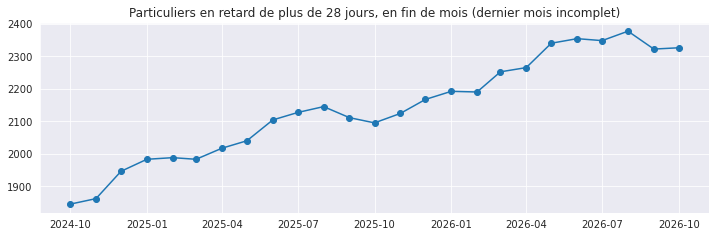

In [15]:
fig, ax = plt.subplots(figsize=(12, 3.5))
evolution.index = evolution.index.to_timestamp()
ax.plot(evolution.index, evolution.values, marker='o')
ax.set_title('Particuliers en retard de plus de 28 jours, en fin de mois (dernier mois incomplet)')
plt.show()

# 3. Les appels téléphoniques

L'appel est prévu à 28 jours de retard ; on part de la **date réelle** notée dans le bloc `B_`. Les calculs portent uniquement sur les **prêts visés par l'appel** : ceux qui ont plus de 28 jours de retard le jour de l'appel (seuil du rapport Koha 207, liste des personnes à appeler) ; les prêts en léger retard à la même date ne sont pas comptés. Premier tableau : part des personnes appelées qui rendent au moins un de ces documents, N jours après l'appel.

Le premier tableau est descriptif : il compare les personnes appelées entre elles selon le résultat de l'appel. Pour mesurer l'**effet** des appels, on ne peut pas comparer des personnes appelées et non appelées : une personne qui rend ses documents avant d'être appelée n'est pas appelée, ce qui fausse toute comparaison entre individus.

Deuxième tableau : **comparaison de périodes**. Le volume d'appels a changé brutalement : environ un tiers des particuliers qui franchissent 28 jours de retard étaient appelés en janvier-mars 2025, près des trois quarts en janvier-mars 2026 (avant les rappels avant échéance massifs d'avril 2026). On compare, pour ces deux trimestres, la part des prêts encore en retard au début d'une fenêtre qui sont rendus avant sa fin :
- **15 à 28 jours** : avant l'âge de l'appel, fenêtre témoin (l'appel ne peut pas jouer) ;
- **29 à 41 jours** : période des appels, avant la lettre de facture de 42 jours ;
- **42 à 56 jours** : après la lettre de facture.

Si les appels font revenir les documents, l'écart 2026 − 2025 doit être nettement plus favorable dans la fenêtre des appels que dans la fenêtre témoin. Comparaison dans le temps, pas une expérience contrôlée : un autre changement survenu entre les deux périodes pourrait jouer. Le test du χ² compare les deux trimestres au niveau prêt (indicatif, les prêts d'une même personne ne sont pas indépendants).

In [16]:
apres_appel.round(1)

,personnes,retard médian à l'appel (j),1 j,3 j,7 j,14 j,28 j
resultat_appel,,,,,,,
usager joint,734,42.0,8.6,18.7,29.8,39.9,48.0
message vocal,1298,41.0,6.0,12.8,20.9,29.7,37.4
téléphone inconnu,288,46.0,1.4,3.5,6.2,14.9,21.2
Ensemble,2320,42.0,6.2,13.5,21.9,31.1,38.7


In [17]:
print("Particuliers franchissant 28 j de retard appelés ensuite :",
      " ; ".join(f"{nom} {v:.0f} %" for nom, v in couverture_periodes.items()))
print(f"Écart sur la période des appels, net de l'écart témoin : {ecart_net:+.1f} pts")
comparaison_periodes.round(1).assign(p=comparaison_periodes['p'].map(lambda v: f'{v:.0e}'))

Particuliers franchissant 28 j de retard appelés ensuite : janv-mars 2025 33 % ; janv-mars 2026 73 %
Écart sur la période des appels, net de l'écart témoin : +17.1 pts


,janv-mars 2025 : rendus %,janv-mars 2026 : rendus %,prêts (2025 / 2026),écart (pts),p
retard,,,,,
15 à 28 j : avant l'âge de l'appel (témoin),62.2,57.8,7500 / 6921,-4.4,6e-08
"29 à 41 j : période des appels, avant la lettre de facture",51.1,63.8,3025 / 2919,12.7,7e-23
42 à 56 j : après la lettre de facture,46.2,50.4,1492 / 1012,4.2,4e-02


**Régularité.** Mois par mois : particuliers qui franchissent 28 jours de retard, appels notés, et part de ces personnes appelées ensuite. Le bloc ne garde que le dernier appel : les volumes anciens sont sous-estimés ; les derniers mois sont incomplets.

In [18]:
regularite.round(0).astype(int).T

,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
franchissent 28 j,447,273,290,366,303,356,296,253,226,203,266,322,334,267,320,297,263,215,234,197,151,79
appels notés,2,1,6,7,14,39,32,37,39,10,18,100,216,253,218,345,275,191,176,23,87,6
jours d'appels,2,1,3,3,4,5,7,11,8,4,4,10,12,8,10,11,7,7,8,3,4,1
appelées ensuite %,30,32,37,32,35,33,33,30,42,33,36,52,72,80,68,65,55,56,60,37,23,0


# 4. Les titres de recette

Par année du contentieux (échéance des prêts, retrouvée dans l'historique ou estimée par la date de la lettre de facture − 42 jours). « Réglés ou annulés » : titres réglés au Trésor public ou annulés après remboursement à la médiathèque — un minimum, car beaucoup de titres n'ont pas de suite notée. Dernières colonnes : particuliers dont un document est resté plus de 180 jours en retard, et part d'entre eux ayant un dossier dans les fichiers de suivi (même année ± 1). Les années récentes sont incomplètes : un titre arrive environ un an et demi après l'échéance.

In [19]:
titres.round(0).astype('Int64')

,dossiers,titres émis (distincts),montant émis (€),réglés ou annulés %,sans titre (< 15 €…),"délai échéance → titre (j, médiane)",personnes > 180 j (Koha),ayant un dossier (± 1 an) %
année du contentieux,,,,,,,,
2018,31,29,1333,31,2,<NA>,<NA>,<NA>
2019,275,248,13095,24,14,<NA>,636,38
2020,312,270,13779,43,24,787,889,28
2021,326,200,11534,50,113,957,450,53
2022,354,215,11421,23,124,347,464,69
2023,335,195,9316,31,131,541,472,71
2024,328,185,9166,21,132,602,477,68
2025,113,49,2059,6,64,569,442,26
2026,11,5,405,40,6,<NA>,140,0


# 5. Anomalies et limites

In [20]:
bloc = renseigne(adh['B_address']) | renseigne(adh['B_address2']) | renseigne(adh['B_country']) | renseigne(adh['B_state'])
sans_retard = bloc & ~adh['borrowernumber'].isin(stock['borrowernumber'])
pd.Series({
    "bloc B_ rempli, aucun document en retard > 28 j": int(sans_retard.sum()),
    "  dont aucun prêt en cours": int((sans_retard & ~adh['borrowernumber'].isin(actuels['borrowernumber'])).sum()),
    "dates d'appel au format JJ/MM/AAAA": int(adh['B_address'].astype(str).str.fullmatch(r'\d{2}/\d{2}/\d{4}').sum()),
    "dates B_ illisibles (appel / tiers / titre)": int(adh[['date_appel_illisible', 'date_tiers_illisible', 'date_titre_illisible']].any(axis=1).sum()),
    "résultat d'appel hors valeurs admises": int((renseigne(adh['B_address2']) & adh['resultat_appel'].isna()).sum()),
    "titre 0 avec montant noté ≥ 15 €": int(((adh['etat_titre'] == '0 (< 15 €)') & (adh['montant_note'] >= SEUIL_TITRE_EUR)).sum()),
    "titre numéroté avec montant noté < 15 €": int(((adh['etat_titre'] == 'numéro') & (adh['montant_note'] < SEUIL_TITRE_EUR)).sum()),
    "particuliers du stock, bloc B_ d'un dossier antérieur": int(part['bloc_dossier_anterieur'].sum()),
}, name='fiches').to_frame()

,fiches
"bloc B_ rempli, aucun document en retard > 28 j",1401
dont aucun prêt en cours,1013
dates d'appel au format JJ/MM/AAAA,1173
dates B_ illisibles (appel / tiers / titre),30
résultat d'appel hors valeurs admises,22
titre 0 avec montant noté ≥ 15 €,31
titre numéroté avec montant noté < 15 €,41
"particuliers du stock, bloc B_ d'un dossier antérieur",125


- Copie de la base rechargée chaque nuit : tout est calculé à la date de fraîcheur ; l'historique commence en juin 2018.
- Le bloc `B_` ne garde qu'une information par étape : l'historique des appels et des dossiers successifs est perdu. Le sens de `B_state = 0` (montant < 15 €) est déduit statistiquement.
- Les comparaisons (appels, rappels avant échéance) sont descriptives, pas des expériences contrôlées.
- Les fichiers de suivi des titres sont saisis à la main ; la valeur du stock repose sur le prix de remplacement Koha.